# Last Statements: Themes, Interpretation and Robustness

## Research question

What recurring expressions appear in Texas's published execution last
statements, and how sensitive are the resulting topic structures to
initialization, short texts and selected formulaic prayers?

## Scope

This project combines traceable text preparation, a 50-person annotation
development sample, and exploratory TF-IDF/NMF topic modeling.

The analysis describes expressed language. It does not determine actual
guilt, sincerity, remorse or psychological state.

The eight manual coding categories and the NMF topics serve different
purposes. Manual labels were not used to fit the topic models.

## Data snapshot

The supplied execution inventory spans December 7, 1982 to October 7, 2026.
It is a fixed snapshot rather than a live inventory.

In [1]:
from pathlib import Path
import sys
import pandas as pd

# Locate the project root from the current directory or its parents.
current = Path.cwd()
ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / "data/processed/model_corpus_v1.csv").exists()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Project data not found. Start Jupyter Notebook "
        "from the project directory."
    )

print("Python:", sys.executable)
print("Project:", ROOT)

corpus = pd.read_csv(
    ROOT / "data/processed/model_corpus_v1.csv",
    keep_default_na=False,
)

print("\nPreparation status:")
display(
    corpus["preparation_status"].value_counts().to_frame("people")
)

Python: /Users/dora/Projects/death-row-last-statements-nlp/.venv/bin/python
Project: /Users/dora/Projects/death-row-last-statements-nlp

Preparation status:


,people
preparation_status,
ready_for_exploration,479
excluded_indirect_summary,1


In [2]:
import hashlib
import json

DATA = ROOT / "data/processed"
RESULTS = ROOT / "results/nmf_v2"

inventory = pd.read_csv(
    DATA / "execution_inventory.csv",
    keep_default_na=False,
)

person_corpus = pd.read_csv(
    DATA / "person_corpus_exploratory_v1.csv",
    keep_default_na=False,
)

annotations = pd.read_csv(
    DATA / "annotation_development_v2.csv",
    dtype=str,
    keep_default_na=False,
)

manifest = json.loads(
    (RESULTS / "run_manifest.json").read_text(encoding="utf-8")
)

# Confirm that the displayed model results use the current model corpus.
model_hash = hashlib.sha256(
    (DATA / "model_corpus_v1.csv").read_bytes()
).hexdigest()

if model_hash != manifest["source_sha256"]:
    raise ValueError("The model corpus differs from the saved NMF run.")

for name, frame in [
    ("Inventory", inventory),
    ("Person corpus", person_corpus),
    ("Annotations", annotations),
]:
    if not frame["execution_number"].is_unique:
        raise ValueError(f"{name} contains duplicate execution IDs.")

overview = pd.DataFrame([
    {
        "Stage": "Execution inventory",
        "People": len(inventory),
        "Meaning": "Records in the supplied index snapshot",
    },
    {
        "Stage": "Candidate corpus",
        "People": len(person_corpus),
        "Meaning": "Person-level documents before modeling preparation",
    },
    {
        "Stage": "Prepared for exploration",
        "People": int(
            corpus["preparation_status"].eq("ready_for_exploration").sum()
        ),
        "Meaning": "Excludes one wholly indirect recorder summary",
    },
    {
        "Stage": "NMF fitted corpus",
        "People": manifest["documents_modeled"],
        "Meaning": "Excludes two additional zero-feature documents",
    },
    {
        "Stage": "Annotation development sample",
        "People": len(annotations),
        "Meaning": "Subset used to develop and adjudicate coding rules",
    },
])

display(overview.set_index("Stage"))
print("Model corpus hash matches the saved NMF run.")
print("Vocabulary features:", manifest["features"])

,People,Meaning
Stage,,
Execution inventory,603,Records in the supplied index snapshot
Candidate corpus,480,Person-level documents before modeling prepara...
Prepared for exploration,479,Excludes one wholly indirect recorder summary
NMF fitted corpus,477,Excludes two additional zero-feature documents
Annotation development sample,50,Subset used to develop and adjudicate coding r...


Model corpus hash matches the saved NMF run.
Vocabulary features: 3196


## Decade composition and sampling

The annotation development sample contains ten people per decade.
This supports examining language across periods, but changes the decade
mix relative to the candidate corpus.

The following comparison describes dataset composition, not changes in
theme prevalence. The 2020s are incomplete in this snapshot.

,Candidate people,Annotated people,Candidate share (%),Annotation share (%)
decade,,,,
1980,19,10,4.0,20.0
1990,109,10,22.7,20.0
2000,216,10,45.0,20.0
2010,104,10,21.7,20.0
2020,32,10,6.7,20.0


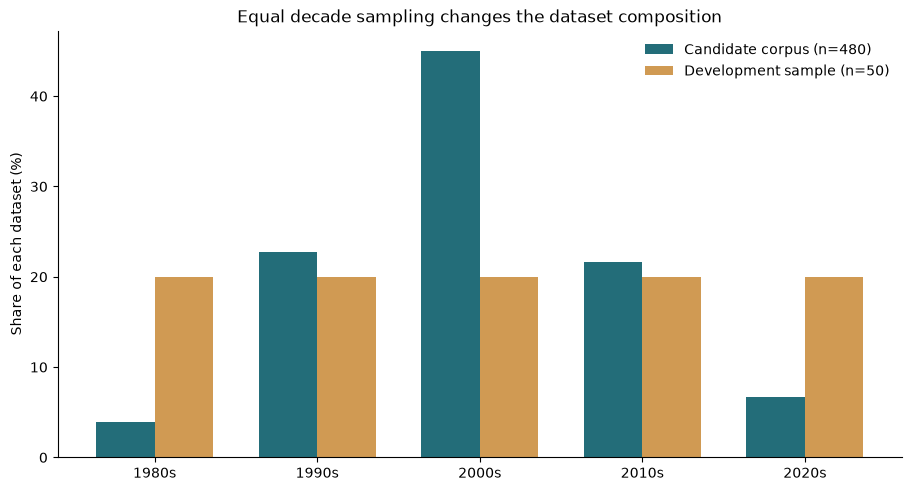

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Use numeric IDs for joining; preserve the original annotation dataframe.
sample_ids = annotations[["execution_number"]].copy()
sample_ids["execution_number"] = pd.to_numeric(
    sample_ids["execution_number"],
    errors="raise",
)

sample_metadata = sample_ids.merge(
    person_corpus[["execution_number", "decade"]],
    on="execution_number",
    how="left",
    validate="one_to_one",
    indicator=True,
)

if not sample_metadata["_merge"].eq("both").all():
    raise ValueError("Some annotated people are missing from the corpus.")

decades = sorted(person_corpus["decade"].unique())

composition = pd.DataFrame({
    "Candidate people": (
        person_corpus.groupby("decade").size()
        .reindex(decades, fill_value=0)
    ),
    "Annotated people": (
        sample_metadata.groupby("decade").size()
        .reindex(decades, fill_value=0)
    ),
})

composition["Candidate share (%)"] = (
    100 * composition["Candidate people"] / len(person_corpus)
)
composition["Annotation share (%)"] = (
    100 * composition["Annotated people"] / len(annotations)
)

display(composition.round(1))

x = np.arange(len(composition))

fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")

ax.bar(
    x - 0.18,
    composition["Candidate share (%)"],
    width=0.36,
    label=f"Candidate corpus (n={len(person_corpus)})",
    color="#236D79",
)
ax.bar(
    x + 0.18,
    composition["Annotation share (%)"],
    width=0.36,
    label=f"Development sample (n={len(annotations)})",
    color="#D09A53",
)

ax.set_xticks(x, [f"{int(d)}s" for d in composition.index])
ax.set_ylabel("Share of each dataset (%)")
ax.set_title("Equal decade sampling changes the dataset composition")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

FIGURES = ROOT / "reports/figures"
FIGURES.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES / "notebook_decade_composition.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Interpretation

The 2000s account for 45% of the candidate corpus but only 20% of the
annotation development sample. The 1980s and 2020s have greater
representation in the development sample than in the candidate corpus.

Consequently, unweighted label percentages from the 50 annotated records
should not be interpreted as estimates for the full corpus.

The topic model uses the full eligible modeling corpus, rather than only
these 50 annotated records.

## Exploratory topic model

TF-IDF represents the prepared statements using unigram and bigram
features. NMF identifies recurring lexical components in this matrix.

Models with four, six and eight topics were explored. The six-topic
solution is the working main analysis, informed by interpretation and
robustness checks; it is not claimed to be uniquely optimal.

The names below are interpretive summaries. Topics may overlap within
a statement and do not replace the eight manual coding categories.

,Interpretive name,Top terms
Topic,,
1,Apology and forgiveness,"sorry, peace, forgive, hope, pain, god, family..."
2,Affection and close relationships,"love, tell, family love, tell family, care, wa..."
3,Case-related denial and explanation,"not, did, know, did not, say, want, no, kill"
4,Scripture and formulaic prayer,"thy, heaven, evil, kingdom, shall, amen, art, ..."
5,Thanks and support — mixed closing language,"thank, like, ready, like thank, warden, jesus,..."
6,Encouragement to remain strong,"strong, stay strong, stay, love, love stay, st..."


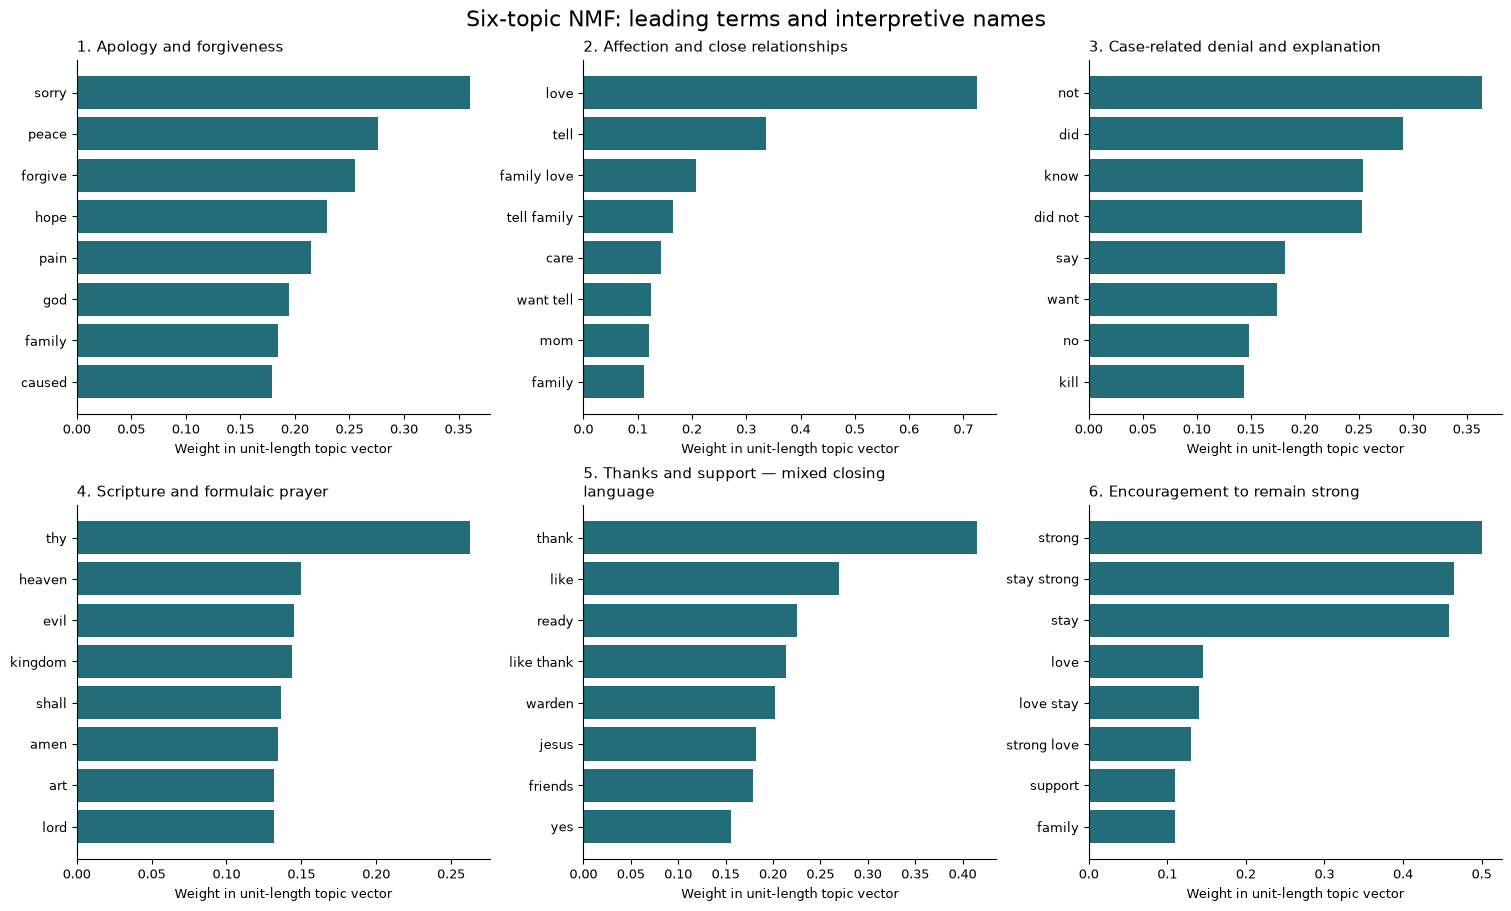

In [4]:
import textwrap

topic_terms = pd.read_csv(
    RESULTS / "topic_terms_k6.csv",
    keep_default_na=False,
)

topic_names = {
    1: "Apology and forgiveness",
    2: "Affection and close relationships",
    3: "Case-related denial and explanation",
    4: "Scripture and formulaic prayer",
    5: "Thanks and support — mixed closing language",
    6: "Encouragement to remain strong",
}

if set(topic_terms["topic"]) != set(topic_names):
    raise ValueError("Unexpected topic IDs.")

topic_overview = pd.DataFrame([
    {
        "Topic": topic,
        "Interpretive name": name,
        "Top terms": ", ".join(
            topic_terms.loc[topic_terms["topic"].eq(topic)]
            .sort_values("rank")
            .head(8)["term"]
        ),
    }
    for topic, name in topic_names.items()
])

display(topic_overview.set_index("Topic"))

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9),
    layout="constrained",
)

for topic, ax in zip(topic_names, axes.flat):
    selected = (
        topic_terms.loc[topic_terms["topic"].eq(topic)]
        .sort_values("rank")
        .head(8)
        .iloc[::-1]
    )

    ax.barh(
        selected["term"],
        selected["term_weight"],
        color="#236D79",
    )
    ax.set_title(
        textwrap.fill(f"{topic}. {topic_names[topic]}", width=38),
        loc="left",
        fontsize=11,
    )
    ax.set_xlabel("Weight in unit-length topic vector", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=9)

fig.suptitle(
    "Six-topic NMF: leading terms and interpretive names",
    fontsize=16,
)

fig.savefig(
    FIGURES / "notebook_topics_k6.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Reading the topic plot

The bars show term weights within each normalized topic vector.
They are not word counts, probabilities or estimates of how many people
expressed a theme.

Several bigrams join words after stopword removal and may cross punctuation
boundaries. They should not be treated as exact source quotations.

Topic 3 requires particular caution: shared words can group denials of
guilt, quoted denials followed by an admission, and uncertainty about what
to say. Numerical stability alone does not establish semantic validity.

Topic 5 combines thanks and support with religious or closing expressions.
A statement can express several themes simultaneously.

## Robustness checks

Three checks examine different sources of variation:

1. Random initialization: five random starts matched to the reference model.
2. Short-text sensitivity: omit 21 modeled statements shorter than ten words.
3. Selected-prayer sensitivity: omit ten records containing specified prayer phrases.

The removal experiments keep the original vocabulary and IDF fixed.
They remove entire records and may also change NMF initialization.

Cosine similarity compares matched topic vectors. High similarity does not
establish semantic validity, and one-to-one matching forces a counterpart
even when two topics are poorly related.

initialization_mean  initialization_min  omit_short_texts  \
k reference_topic                                                              
6 1                              1.000               0.998             0.994   
  2                              0.944               0.792             0.849   
  3                              1.000               0.999             0.995   
  4                              1.000               0.999             1.000   
  5                              0.988               0.940             0.974   
  6                              0.761               0.054             0.988   
8 1                              0.993               0.990             0.989   
  2                              0.853               0.788             0.769   
  3                              0.971               0.859             0.995   
  4                              0.994               0.990             0.999   
  5                              0.326               0.118             0.995   
  6                              0.947               0.746             0.992   
  7                              0.998               0.993             0.278   
  8                              0.855               0.813             0.954   

                   omit_selected_prayers  
k reference_topic                         
6 1                                0.974  
  2                                0.999  
  3                                0.998  
  4                                0.293  
  5                                0.908  
  6                                1.000  
8 1                                0.980  
  2                                0.993  
  3                                0.998  
  4                                0.116  
  5                                0.994  
  6                                0.991  
  7                                1.000  
  8                                0.999

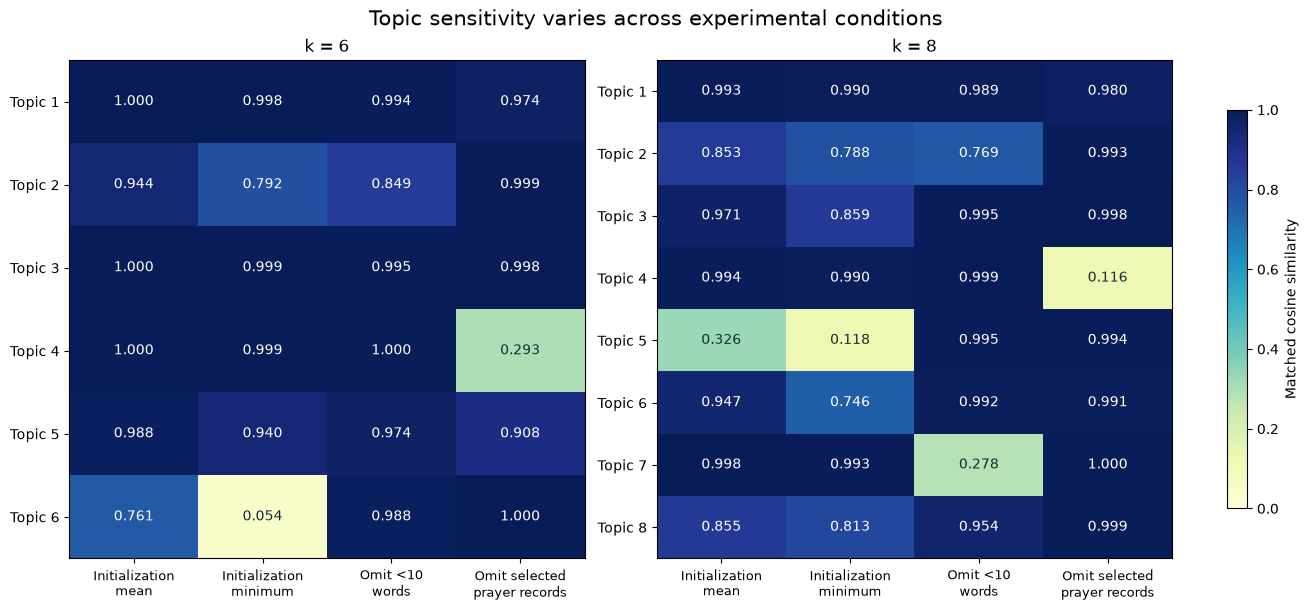

In [5]:
stability = pd.read_csv(
    ROOT / "results/nmf_stability_v1/matched_topics.csv"
)
short_check = pd.read_csv(
    ROOT / "results/short_text_sensitivity_v1/matched_topics.csv"
)
prayer_check = pd.read_csv(
    ROOT / "results/prayer_sensitivity_v1/matched_topics.csv"
)

# Keep each topic's average and weakest initialization match separate.
init_summary = (
    stability.groupby(["k", "reference_topic"])
    .agg(
        initialization_mean=("cosine_similarity", "mean"),
        initialization_min=("cosine_similarity", "min"),
    )
)

short_summary = (
    short_check.set_index(["k", "reference_topic"])
    [["cosine_similarity"]]
    .rename(columns={"cosine_similarity": "omit_short_texts"})
)

prayer_summary = (
    prayer_check.set_index(["k", "reference_topic"])
    [["cosine_similarity"]]
    .rename(columns={"cosine_similarity": "omit_selected_prayers"})
)

robustness = (
    init_summary
    .join(short_summary, how="inner", validate="one_to_one")
    .join(prayer_summary, how="inner", validate="one_to_one")
    .sort_index()
)

if len(robustness) != 14 or robustness.isna().any().any():
    raise ValueError("Unexpected or incomplete robustness results.")

display(robustness.round(3))

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 6),
    layout="constrained",
)

column_labels = [
    "Initialization\nmean",
    "Initialization\nminimum",
    "Omit <10\nwords",
    "Omit selected\nprayer records",
]

for ax, k in zip(axes, [6, 8]):
    selected = robustness.xs(k, level="k")
    matrix = selected.to_numpy()

    image = ax.imshow(
        matrix,
        vmin=0,
        vmax=1,
        cmap="YlGnBu",
        aspect="auto",
    )

    ax.set_xticks(range(4), column_labels, fontsize=9)
    ax.set_yticks(
        range(len(selected)),
        [f"Topic {int(t)}" for t in selected.index],
    )
    ax.set_title(f"k = {k}")

    for row in range(matrix.shape[0]):
        for col in range(matrix.shape[1]):
            value = matrix[row, col]
            ax.text(
                col, row, f"{value:.3f}",
                ha="center", va="center",
                color="white" if value > 0.65 else "#172B36",
            )

fig.colorbar(
    image,
    ax=axes.tolist(),
    label="Matched cosine similarity",
    shrink=0.8,
)
fig.suptitle(
    "Topic sensitivity varies across experimental conditions",
    fontsize=15,
)

fig.savefig(
    FIGURES / "notebook_robustness.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### Interpretation and model choice

The six-topic model is retained as the main exploratory summary, with the
eight-topic model as a supplement. This balances interpretability,
compactness and the observed robustness results; it does not establish
a uniquely optimal topic count.

The six-topic solution is not uniformly stable: its encouragement
component has a minimum initialization similarity of 0.054.

In the eight-topic solution, farewell/procedural readiness changes
substantially when short texts are omitted (similarity 0.278).
This supports retaining short statements in the main analysis.

Removing selected prayer records changes the formulaic-prayer component
substantially: similarity is 0.293 for six topics and 0.116 for eight.
Because whole records are removed, the effect cannot be attributed
solely to their prayer passages.

These checks measure lexical robustness, not psychological validity.

## Qualitative error analysis: stable words, different meanings

Topic 3 is numerically stable, but its high-weight statements do not
necessarily express the same stance.

Three deliberately selected examples illustrate the distinction:

- Execution 117 explicitly denies killing anyone.
- Execution 391 expresses uncertainty about what to say.
- Execution 499 quotes other people's denial, then explicitly admits
  committing the murders.

These examples diagnose interpretation limits; they are not a random
evaluation sample or an estimate of topic precision.

In [6]:
from IPython.display import Markdown, display

weights_k6 = pd.read_csv(
    RESULTS / "document_weights_k6.csv",
    keep_default_na=False,
)

examples = pd.DataFrame({
    "execution_number": [117, 391, 499],
    "Interpretation": [
        "Explicit denial of killing",
        "Uncertainty about what to say",
        "Quoted denial followed by an explicit admission",
    ],
})

examples = (
    examples
    .merge(
        weights_k6[["execution_number", "topic_3"]],
        on="execution_number",
        how="left",
        validate="one_to_one",
    )
    .merge(
        corpus[["execution_number", "model_text", "source_url"]],
        on="execution_number",
        how="left",
        validate="one_to_one",
    )
)

if examples[["topic_3", "model_text"]].isna().any().any():
    raise ValueError("An example is missing from the corpus or model output.")

display(
    examples[
        ["execution_number", "Interpretation", "topic_3"]
    ].rename(columns={
        "execution_number": "Execution",
        "topic_3": "Topic 3 coefficient",
    }).set_index("Execution")
)

for _, row in examples.iterrows():
    display(Markdown(
        f"### Execution {int(row['execution_number'])}\n\n"
        f"**Reading:** {row['Interpretation']}\n\n"
        f"[Source statement]({row['source_url']})"
    ))
    # Render the stored text as plain text, without interpreting it as Markdown.
    print(row["model_text"])

,Interpretation,Topic 3 coefficient
Execution,,
117,Explicit denial of killing,0.432767
391,Uncertainty about what to say,0.403221
499,Quoted denial followed by an explicit admission,0.361016


### Execution 117

**Reading:** Explicit denial of killing

[Source statement](https://www.tdcj.texas.gov/death_row/dr_info/westleyanthonylast.html)

I want you to know that I did not kill anyone. I love you all.


### Execution 391

**Reading:** Uncertainty about what to say

[Source statement](https://www.tdcj.texas.gov/death_row/dr_info/clarkjameslast.html)

Uh, I don't know, Um, I don't know what to say. I don't know. . I didn't know anybody was there. Howdy.


### Execution 499

**Reading:** Quoted denial followed by an explicit admission

[Source statement](https://www.tdcj.texas.gov/death_row/dr_info/chesterelroylast.html)

I just want to say I don't want you to have hate in your heart for me, because I took your loved one. I know it doesn't mean anything; I told the truth because I feel like you should know who killed your loved one. God watches everything. Don't hate me, if you do, you'll have to deal with Him later. For me, live your life but don't hate me. I'm sorry for taking your loved one. Ms. Suzy, Susan, thank you for fighting for me in the courts. Thank you for supporting me for all these years. Elroy Chester wasn't a bad man, I knew me. A lot of people say I didn't commit those murders, I really did it. That's my statement. Warden, you can go ahead.


## Conclusions

The six-topic solution provides a useful exploratory summary of recurring
expressions involving apology and forgiveness, affection, case-related
denial and explanation, formulaic prayer, thanks and support, and
encouragement.

Three findings are particularly informative:

1. Preprocessing affects interpretation. Harmonizing contraction spellings
   removed a topic dominated by tokenization fragments.
2. Robustness depends on the component and experimental condition.
   Short statements contribute to the separately identified readiness
   component in the eight-topic model, while selected prayer records
   strongly influence the formulaic-prayer component.
3. Lexical stability does not guarantee semantic validity. Negation,
   quoted speech and contrasting positions can share similar vocabulary.

Short texts and prayer-containing records remain in the main analysis.
Their temporary removal was a sensitivity experiment, not a judgment
that they were invalid observations.

## Limitations

- The corpus reflects published records, source omissions, redactions
  and transcription or translation choices.
- Text preparation is traceable but does not establish complete
  transcription accuracy or resolve all upstream date and section issues.
- The 50 annotated records were used for guideline development and
  non-blind adjudication, not independent model evaluation.
- English-oriented lexical features do not reliably capture speaker
  attribution, negation scope, cultural meaning or psychological state.
- Five random initializations and two record-removal experiments provide
  limited robustness evidence, not proof of generalizability.
- Topic coefficients are not probabilities or population theme prevalence.

## Reproducibility and assistance

This notebook reads saved model outputs rather than fitting the models.
The accompanying scripts contain the preparation, fitting and robustness
procedures. The model-corpus hash is checked against the saved run manifest.

AI assisted with code, documentation and interpretation discussions.
The project owner reviewed and approved the v2 manual coding decisions.
These discussions do not constitute independent expert validation.

## Source

Texas Department of Criminal Justice:
[Executed Inmates](https://www.tdcj.texas.gov/death_row/executed_inmates.html).

Statement-level source links are retained in the corpus.